# AIDA 2154 Final Project – 02 Segmentation

**Data version 2** (`shared/synthetic-data/kit-cards/`), generated from cleaned requests version 1.1.

**Question:** Can a simple, transparent pipeline find each object on a card as one region with a well-fitting box, providing suitable regions for the baseline classifier in notebook 03?

The pipeline uses classical methods covered in the course: denoising, local paper-colour estimation, colour or grayscale differences, thresholding, morphology, and connected-component detection. Predicted regions are matched to the recorded object boxes to assess detection and box fit. Missed objects, split objects, merged regions, and false alarms are reported separately.

**Use of the splits.** Training cards are used to inspect failures and develop a small settings grid. The grid and selection rule are fixed before comparing settings on the 120 validation cards; one later change, a band left out along the card edges, is described in section C. The selected setting is then frozen. Test images are not opened, measured, or used for development in this notebook; only their label records are loaded and then filtered out. The complete frozen detection-and-classification pipeline will be evaluated on test once, at the end of the project.

All cards are computer-generated and contain no personal information.

In [1]:
import hashlib
import json
from itertools import product
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from PIL import Image, ImageDraw

DATA_VERSION = "2"
SD = Path("../../../shared/synthetic-data")          # data version 2
KIT = SD / "kit-cards"
OUTPUT_DIR = Path("../outputs")
FIGURE_DIR = Path("../figures")
OUTPUT_DIR.mkdir(exist_ok=True)
FIGURE_DIR.mkdir(exist_ok=True)

ITEMS = ["access_badge", "safety_vest", "hard_hat", "laptop", "phone"]
DEV_SPLITS = ["train", "validation"]  # only development images are read; metadata includes all splits

# Only truly empty cells become missing (NaN); text such as "NA" stays as written
manifest = pd.read_csv(KIT / "manifest.csv", keep_default_na=False, na_values=[""])
objects = pd.read_csv(KIT / "icon_instances.csv", keep_default_na=False, na_values=[""])
generation = json.loads((KIT / "outputs/generation_info.json").read_text())
cleaning_info = json.loads((SD / "cleaning/output/requests_cleaned_info.json").read_text())

sha = lambda path: hashlib.sha256(Path(path).read_bytes()).hexdigest()
cards_match_cleaning = (generation["input_sha256"] == sha(SD / "cleaning/output/requests_cleaned.csv")
                        == cleaning_info["output_sha256"]
                        and generation["input_record"]["cleaning_version"] == cleaning_info["cleaning_version"])
assert cards_match_cleaning, "The recorded card-generation input doesn't match the current cleaned file"

# Check card-object links before filtering, so a wrong split can't silently include or exclude records
assert manifest["card_id"].notna().all() and manifest["card_id"].is_unique, "Manifest card IDs are missing or duplicated"
linked = objects.merge(manifest[["card_id", "split"]], on="card_id", how="left", suffixes=("_object", "_card"),
                       validate="many_to_one")
assert linked["split_card"].notna().all(), "An object belongs to an unknown card"
assert linked["split_object"].eq(linked["split_card"]).all(), "An object's split differs from its card"

dev_cards = manifest[manifest["split"].isin(DEV_SPLITS)].reset_index(drop=True)
dev_objects = objects[objects["split"].isin(DEV_SPLITS)].reset_index(drop=True)
assert dev_cards["split"].value_counts().to_dict() == {"train": 360, "validation": 120}, "Unexpected development split sizes"

# Fingerprints saved with the frozen settings: each development image (name and contents) and both label files
image_records = [{"file_name": f, "sha256": sha(KIT / "images" / f)} for f in sorted(dev_cards["file_name"])]
dev_images_sha256 = hashlib.sha256(json.dumps(image_records, sort_keys=True).encode()).hexdigest()
label_sha256 = {name: sha(KIT / name) for name in ["manifest.csv", "icon_instances.csv"]}

print(f"Data version {DATA_VERSION}; cards made from cleaning version {generation['input_record']['cleaning_version']}")
print(f"Development cards: {(dev_cards['split'] == 'train').sum()} training, {(dev_cards['split'] == 'validation').sum()} validation; "
      f"{len(dev_objects):,} drawn objects ({(dev_objects['role'] == 'kit_item').sum()} kit items)")

Data version 2; cards made from cleaning version 1.1
Development cards: 360 training, 120 validation; 1,240 drawn objects (958 kit items)


## A. How regions are matched to objects

The matching rules are fixed before any setting is compared, so every setting is scored the same way.

A region **overlaps** an object when their bounding boxes share a positive area. Boxes that only meet at an edge or corner do not overlap. This is a box-based association rule; it does not establish that the region's foreground pixels belong to that object. Even a small overlap counts under this rule.

### Region outcomes

Each region is classified as:

- **False region:** it overlaps no recorded object.
- **Merged region:** it overlaps two or more recorded objects.
- **Single-object region:** it overlaps exactly one recorded object.

Recorded objects include both kit items and background objects.

### Object outcomes

Each object receives one outcome, checked in this order:

1. **Missed:** no region overlaps it.
2. **Merged:** a merged region overlaps it. A merge never counts as a clean detection, even if its box fits the object.
3. **Split:** two or more regions overlap it.
4. **One region, good fit:** exactly one region overlaps it, that region overlaps no other object, and the boxes have **IoU ≥ 0.5**.
5. **One region, poor fit:** the same one-to-one match, but with IoU < 0.5.

**IoU**, or intersection over union, is the shared area of the two boxes divided by their total combined area, counting the shared area only once.

These outcomes are mutually exclusive. If an object is involved in both a merge and a split, it is reported as merged because that check comes first.

Only outcome 4 counts as a **clean detection**. It is one-to-one: the object has one region, and that region has one object, so two regions cannot both receive credit for the same object.

### Main measure

The main measure is the **share of kit items with a clean detection**. False regions, merged regions, and the other object outcomes are reported alongside it.

Clean detections should make classification easier, but notebook 03's end-to-end evaluation will show whether imperfect regions still lead to correct item-presence decisions. A classifier may recognise an item even when its crop fits poorly.

Objects missed during segmentation remain in the evaluation population; they are not excluded because no suitable crop was found. Notebook 03 evaluates the complete pipeline's item-presence decisions separately.

In [2]:
IOU_GOOD = 0.5


def iou(r, o):
    inter = max(0, min(r[2], o[2]) - max(r[0], o[0])) * max(0, min(r[3], o[3]) - max(r[1], o[1]))
    return inter / ((r[2] - r[0]) * (r[3] - r[1]) + (o[2] - o[0]) * (o[3] - o[1]) - inter)


def overlaps(r, o):
    # Positive shared area; boxes that only meet at an edge or corner do not overlap
    return r[0] < o[2] and r[2] > o[0] and r[1] < o[3] and r[3] > o[1]


def match_card(regions, card_objects):
    # Returns (region rows, object rows) for one card using the rules above
    boxes = [(o.x0, o.y0, o.x1, o.y1) for o in card_objects.itertuples()]
    overlapped_by_region = [[j for j, b in enumerate(boxes) if overlaps(r, b)] for r in regions]
    region_rows = []
    for k, (r, hits) in enumerate(zip(regions, overlapped_by_region)):
        kind = "false" if not hits else ("merged" if len(hits) > 1 else "single")
        region_rows.append({"region": k, "x0": r[0], "y0": r[1], "x1": r[2], "y1": r[3], "region_type": kind,
                            "objects_overlapped": len(hits), "object_index": hits[0] if kind == "single" else None})
    object_rows = []
    # object_index is the zero-based position within card_objects for this card (saved later together with card_id)
    for j, (o, b) in enumerate(zip(card_objects.itertuples(), boxes)):
        hits = [k for k, t in enumerate(overlapped_by_region) if j in t]
        best = max((iou(regions[k], b) for k in hits), default=0.0)
        if not hits:
            outcome = "missed"
        elif any(len(overlapped_by_region[k]) > 1 for k in hits):
            outcome = "merged"
        elif len(hits) > 1:
            outcome = "split"
        else:
            outcome = "one_region_good_fit" if best >= IOU_GOOD else "one_region_poor_fit"
        object_rows.append({"object_index": j, "outcome": outcome, "best_iou": best, "regions_overlapping": len(hits)})
    return region_rows, object_rows


# Self-test of the rules on hand-made boxes, so the matching logic is verified before it is used
_objs = pd.DataFrame({"x0": [10, 100, 200, 300], "y0": [10, 10, 10, 10], "x1": [50, 140, 240, 340], "y1": [50, 50, 50, 50]})
_regions = [(10, 10, 50, 50),          # object 0: good fit
            (95, 5, 245, 55),          # overlaps objects 1 and 2: merged
            (300, 10, 315, 50), (320, 10, 340, 50),   # object 3: split
            (400, 10, 420, 30)]        # false region
_r, _o = match_card(_regions, _objs)
assert [x["outcome"] for x in _o] == ["one_region_good_fit", "merged", "merged", "split"]
assert [x["region_type"] for x in _r] == ["single", "merged", "single", "single", "false"]
_, _missed = match_card([], _objs)                                  # no regions: every object is missed
assert all(o["outcome"] == "missed" for o in _missed)
_, _poor = match_card([(10, 10, 20, 20)], _objs.iloc[:1])           # small region over one object: poor fit
assert _poor[0]["outcome"] == "one_region_poor_fit"
assert not overlaps((0, 0, 10, 10), (10, 0, 20, 10))                # meeting at an edge is not an overlap
_, _edge = match_card([(10, 10, 30, 50)], _objs.iloc[:1])           # IoU exactly 0.5 counts as a good fit
assert _edge[0]["best_iou"] == 0.5 and _edge[0]["outcome"] == "one_region_good_fit"
print("Matching rules pass their self-test (good fit, poor fit, merged, split, missed, false region, edge contact, IoU = 0.5)")

Matching rules pass their self-test (good fit, poor fit, merged, split, missed, false region, edge contact, IoU = 0.5)


## B. Reconciling the pilot

The shared segmentation pilot (`shared/synthetic-data/checks/`) reported its best training setting as 568 objects found as one region with a good fit, 340 with a poor fit, 11 split and 1 missed. Those four groups add up to all 920 training objects. Its 65 merged regions were a **separate count of regions**, not objects: under the pilot's rule, an object counted as "found as one region" whenever exactly one region overlapped it, even if that region also covered another object.

This cell reruns the pilot's best setting on the same training cards and scores it twice: once with the pilot's original counting rule, to confirm the explanation above, and once with the new matching rules, to show how many of the pilot's "one region" objects were actually part of a merge. It also counts merged regions, so the two counting units (regions and objects) can be compared directly.

"Best" refers to the pilot's original scoring rule. This rerun assesses that setting under the stricter matching rules; it does not assume the setting will remain best.

In [3]:
PILOT_CONTENT = (slice(37, 318), slice(2, 478))   # the pilot's area: below the header, inside the 2-pixel border
GRAY_WEIGHTS = np.array([0.114, 0.587, 0.299], dtype=np.float32)   # OpenCV loads images as blue-green-red


def find_regions(diff, threshold, open_size, close_size, min_pixels, area, connectivity=8):
    mask = (diff > threshold).astype(np.uint8)
    if open_size:
        mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((open_size, open_size), np.uint8))
    if close_size:
        mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (close_size, close_size)))
    _, _, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=connectivity)
    x_off, y_off = area[1].start, area[0].start          # convert back to card coordinates
    return [(int(s[0]) + x_off, int(s[1]) + y_off, int(s[0] + s[2]) + x_off, int(s[1] + s[3]) + y_off)
            for s in stats[1:] if s[4] >= min_pixels]


def pilot_regions(path):
    # The pilot's best setting E: median 5, Gaussian background (sigma 25), colour distance > 20, open 3, close 9
    image = cv2.imread(str(path))
    if image is None:
        raise ValueError(f"Could not open image: {path}")
    content = cv2.medianBlur(image, 5)[PILOT_CONTENT].astype(np.float32)
    diff = np.linalg.norm(content - cv2.GaussianBlur(content, (0, 0), 25), axis=2)
    return find_regions(diff, 20, 3, 9, 30, PILOT_CONTENT)


def pilot_rule(regions, card_objects):
    # The pilot's original rule: count the regions overlapping each object, ignoring whether a region also covers another object
    out = []
    for o in card_objects.itertuples():
        box = (o.x0, o.y0, o.x1, o.y1)
        hits = [r for r in regions if overlaps(r, box)]
        if not hits:
            out.append("missed")
        elif len(hits) > 1:
            out.append("split")
        else:
            out.append("one_region_good_fit" if iou(hits[0], box) >= IOU_GOOD else "one_region_poor_fit")
    return out


train_cards = dev_cards[dev_cards["split"] == "train"]
pilot_rows, old_rule, merged_regions = [], [], 0
for card in train_cards.itertuples():
    card_objects = dev_objects[dev_objects["card_id"] == card.card_id].reset_index(drop=True)
    found = pilot_regions(KIT / "images" / card.file_name)
    region_rows, obj_rows = match_card(found, card_objects)
    merged_regions += sum(r["region_type"] == "merged" for r in region_rows)
    pilot_rows.extend(obj_rows)
    old_rule.extend(pilot_rule(found, card_objects))

PILOT_OUTCOMES = ["one_region_good_fit", "one_region_poor_fit", "merged", "split", "missed"]
pilot = pd.DataFrame({
    "pilot's original rule": pd.Series(old_rule).value_counts(),
    "new matching rules": pd.Series([r["outcome"] for r in pilot_rows]).value_counts(),
}).reindex(PILOT_OUTCOMES).fillna(0).astype(int)
expected_objects = int((dev_objects["split"] == "train").sum())
assert len(pilot_rows) == len(old_rule) == expected_objects, "Not every training object was scored"
assert (pilot.sum() == expected_objects).all(), "Outcome counts don't add up to all training objects"
pilot.to_csv(OUTPUT_DIR / "pilot_reconciliation_train.csv")
print(f"Pilot setting E on {len(train_cards)} training cards, {expected_objects} objects:")
display(pilot)
print(f"Merged regions (each covering two or more objects): {merged_regions}")

Pilot setting E on 360 training cards, 920 objects:


,pilot's original rule,new matching rules
one_region_good_fit,568,568
one_region_poor_fit,340,201
merged,0,148
split,11,2
missed,1,1


Merged regions (each covering two or more objects): 65


## C. The pipeline and the settings grid

**Fixed for every setting** (recorded in the frozen settings file):
- **Content area:** rows 46–309 and columns 10–469. This leaves out the 36-pixel header plus a 10-pixel band along the header and the card edges. The generator keeps every object at least 14 pixels from the header and edges (the closest recorded box starts at row 50 and column 15), so no object is cut off.

  *This band was added during development.* A first version used the pilot's area (everything below the header, inside the 2-pixel border). Its false regions were mostly thin strips along the header edge and the card border: 10 of the 27 false regions on training cards started at the header edge, and most of the rest touched the border. This was first noticed in the validation examples and then confirmed on training cards. Because the change was prompted partly by validation, it is one more reason the validation figures below are selection results rather than unbiased estimates.
- **Denoising:** median filter, 5 × 5 pixels.
- **Opening:** 3 × 3 square (removes isolated noise pixels). **Minimum region size:** 30 pixels. **Connectivity:** 8 neighbours.

**Compared in the grid (2 × 2 × 2 × 2 = 16 settings):**
- **Background estimate:** *Gaussian* (the pilot's: a heavy blur of the card, sigma 25 pixels) or *masked*. The masked estimate excludes likely foreground pixels identified by a preliminary colour-difference mask (colour distance above 16 from the Gaussian background, widened by a 7 × 7 square), then estimates the background from the remaining pixels (a blur of those pixels divided by a blur of the mask, sigma 25; where too few remaining pixels are nearby, with a weight below 0.001, the Gaussian estimate is used instead). Some faint foreground pixels may remain in that estimate. The Gaussian estimate can absorb colour from large objects into the "paper", which is one plausible reason for the pilot's poorly fitting boxes; the masked estimate tests that idea. Both masked variants use this colour-based preliminary mask, so the masked grayscale setting is not an entirely grayscale pipeline.
- **Difference measure:** *colour* (distance in red-green-blue) or *grayscale* (brightness difference). Notebook 01 found hard hats and vests weakest in grayscale.
- **Threshold:** low or high, set at about 1.5× and 2.5× the empty-paper reference from notebook 01 for that measure: colour 16 or 26 (reference 10.5), grayscale 9 or 15 (reference 6.0). The units differ because the measures use different scales.
- **Closing:** 7 or 11 pixel ellipse (joins nearby parts of one drawing; larger values risk joining neighbours).

**Selection rule:** the rule below is fixed before running this revised 16-setting comparison. Validation examples informed earlier development, including the content-area change, so the reported validation results are development and selection results, not an independent performance estimate.

The chosen setting is the one with the highest share of clean kit-item detections on validation. Ties are broken by, in order: fewer merged regions, fewer false regions, higher median IoU of clean detections, smaller closing, then the fixed grid order. All comparisons use unrounded values; numbers are rounded only for display.

Every setting is also scored on training cards, which are used to look at failures, but the choice uses validation only.

Poor box fit was the most common failure recorded by the pilot, so it is the first issue to investigate. The background estimate is a plausible cause, not an established one.

In [4]:
MEDIAN, OPEN, MIN_PIXELS, CONNECTIVITY, SIGMA = 5, 3, 30, 8, 25
EDGE_BAND = 10        # pixels left out along the header and card edges (objects are always at least 14 px away)
CONTENT = (slice(36 + EDGE_BAND, 320 - EDGE_BAND), slice(EDGE_BAND, 480 - EDGE_BAND))
assert ((dev_objects["x0"] >= CONTENT[1].start) & (dev_objects["y0"] >= CONTENT[0].start)
        & (dev_objects["x1"] <= CONTENT[1].stop) & (dev_objects["y1"] <= CONTENT[0].stop)).all(), \
    "The content area cuts off a recorded development object"
PRELIM_THRESHOLD, PRELIM_DILATE, MIN_WEIGHT = 16, 7, 1e-3   # masked background: preliminary colour mask and fallback
GRID = [{"background": bg, "measure": me, "threshold_level": lv, "close": cl}
        for bg, me, lv, cl in product(["gaussian", "masked"], ["colour", "gray"], ["low", "high"], [7, 11])]
THRESHOLDS = {("colour", "low"): 16, ("colour", "high"): 26, ("gray", "low"): 9, ("gray", "high"): 15}
for g in GRID:
    g["threshold"] = THRESHOLDS[(g["measure"], g["threshold_level"])]
    g["name"] = f"{g['background']} | {g['measure']} > {g['threshold']} | close {g['close']}"


def difference_maps(path):
    # The four background x measure difference maps for one card (computed once, reused by every threshold and closing)
    image = cv2.imread(str(path))
    if image is None:
        raise ValueError(f"Could not open image: {path}")
    content = cv2.medianBlur(image, MEDIAN)[CONTENT].astype(np.float32)
    gaussian = cv2.GaussianBlur(content, (0, 0), SIGMA)
    # Masked estimate: drop likely foreground (preliminary colour mask), estimate the background from the remaining pixels
    first_pass = np.linalg.norm(content - gaussian, axis=2) > PRELIM_THRESHOLD
    first_pass = cv2.dilate(first_pass.astype(np.uint8), np.ones((PRELIM_DILATE, PRELIM_DILATE), np.uint8)).astype(bool)
    remaining = (~first_pass).astype(np.float32)
    weight = cv2.GaussianBlur(remaining, (0, 0), SIGMA)
    masked = cv2.GaussianBlur(content * remaining[..., None], (0, 0), SIGMA) / np.maximum(weight, MIN_WEIGHT)[..., None]
    masked = np.where(weight[..., None] > MIN_WEIGHT, masked, gaussian)     # Gaussian fallback where weight is too low
    maps = {}
    for name, background in [("gaussian", gaussian), ("masked", masked)]:
        maps[(name, "colour")] = np.linalg.norm(content - background, axis=2)
        maps[(name, "gray")] = np.abs((content - background) @ GRAY_WEIGHTS)
    return maps


region_rows, object_rows = [], []
for card in dev_cards.itertuples():
    card_objects = dev_objects[dev_objects["card_id"] == card.card_id].reset_index(drop=True)
    maps = difference_maps(KIT / "images" / card.file_name)
    for g in GRID:
        found = find_regions(maps[(g["background"], g["measure"])], g["threshold"], OPEN, g["close"], MIN_PIXELS, CONTENT, CONNECTIVITY)
        regs, objs = match_card(found, card_objects)
        for r in regs:
            region_rows.append({"setting": g["name"], "card_id": card.card_id, "split": card.split, **r})
        for o in objs:
            src = card_objects.iloc[o["object_index"]]
            object_rows.append({"setting": g["name"], "card_id": card.card_id, "split": card.split, "role": src.role,
                                "object": src.object, "style": src.style, "size_band": src.size_band,
                                "contrast_band": src.contrast_band, **o})
grid_regions = pd.DataFrame(region_rows)
grid_objects = pd.DataFrame(object_rows)
print(f"Scored {len(GRID)} settings on {len(dev_cards)} cards: {len(grid_objects):,} object outcomes, {len(grid_regions):,} regions")

Scored 16 settings on 480 cards: 19,840 object outcomes, 19,553 regions


In [5]:
OUTCOMES = ["one_region_good_fit", "one_region_poor_fit", "merged", "split", "missed"]


def summarise(split):
    objs = grid_objects[grid_objects["split"] == split]
    regs = grid_regions[grid_regions["split"] == split]
    kit = objs[objs["role"] == "kit_item"]
    t = kit.pivot_table(index="setting", columns="outcome", values="card_id", aggfunc="count").reindex(columns=OUTCOMES, fill_value=0).fillna(0).astype(int)
    t.insert(0, "kit_items", t.sum(axis=1))
    t["clean_%"] = 100 * t["one_region_good_fit"] / t["kit_items"]          # unrounded; rounded only for display
    t["merged_regions"] = regs[regs["region_type"] == "merged"].groupby("setting").size().reindex(t.index, fill_value=0)
    t["false_regions"] = regs[regs["region_type"] == "false"].groupby("setting").size().reindex(t.index, fill_value=0)
    t["median_clean_iou"] = kit[kit["outcome"] == "one_region_good_fit"].groupby("setting")["best_iou"].median().reindex(t.index)
    settings = pd.DataFrame(GRID).set_index("name")
    t = t.join(settings[["background", "measure", "threshold", "close"]])
    t["grid_order"] = t.index.map({g["name"]: i for i, g in enumerate(GRID)})
    return t


grid_train, grid_validation = summarise("train"), summarise("validation")
ROUND = {"clean_%": 1, "median_clean_iou": 3}
grid_train.round(ROUND).to_csv(OUTPUT_DIR / "segmentation_grid_train.csv")
grid_validation.round(ROUND).to_csv(OUTPUT_DIR / "segmentation_grid_validation.csv")

# Selection on validation, by the rule fixed in section C
ranked = grid_validation.sort_values(["clean_%", "merged_regions", "false_regions", "median_clean_iou", "close", "grid_order"],
                                     ascending=[False, True, True, False, True, True], na_position="last")
CHOSEN = ranked.index[0]
show = ["kit_items", "clean_%", "one_region_good_fit", "one_region_poor_fit", "merged", "split", "missed",
        "merged_regions", "false_regions", "median_clean_iou"]
print("Validation results, best first: kit-item outcomes, with merged and false region counts across all regions:")
display(ranked[show].round(ROUND))
print(f"Chosen setting: {CHOSEN}")
print("Training results for the same settings (used for inspection, not for the choice):")
display(grid_train.loc[ranked.index, show].round(ROUND))

Validation results, best first: kit-item outcomes, with merged and false region counts across all regions:


,kit_items,clean_%,one_region_good_fit,one_region_poor_fit,merged,split,missed,merged_regions,false_regions,median_clean_iou
setting,,,,,,,,,,
masked | gray > 9 | close 11,238,99.6,237,1,0,0,0,0,2,0.830
masked | colour > 16 | close 11,238,99.2,236,2,0,0,0,0,1,0.869
masked | gray > 9 | close 7,238,98.3,234,1,0,3,0,0,2,0.830
masked | colour > 16 | close 7,238,97.5,232,2,0,4,0,0,1,0.870
masked | colour > 26 | close 11,238,95.4,227,6,0,0,5,0,1,0.844
masked | colour > 26 | close 7,238,95.4,227,6,0,0,5,0,1,0.843
masked | gray > 15 | close 11,238,93.3,222,6,0,3,7,0,1,0.806
masked | gray > 15 | close 7,238,92.0,219,6,0,6,7,0,1,0.807
gaussian | colour > 26 | close 11,238,73.1,174,38,16,3,7,9,0,0.740


Chosen setting: masked | gray > 9 | close 11
Training results for the same settings (used for inspection, not for the choice):


,kit_items,clean_%,one_region_good_fit,one_region_poor_fit,merged,split,missed,merged_regions,false_regions,median_clean_iou
setting,,,,,,,,,,
masked | gray > 9 | close 11,720,99.4,716,3,0,1,0,0,0,0.832
masked | colour > 16 | close 11,720,99.6,717,2,0,1,0,0,0,0.863
masked | gray > 9 | close 7,720,98.9,712,3,0,5,0,0,1,0.832
masked | colour > 16 | close 7,720,99.6,717,2,0,1,0,0,1,0.863
masked | colour > 26 | close 11,720,96.8,697,14,0,6,3,0,0,0.833
masked | colour > 26 | close 7,720,96.4,694,14,0,9,3,0,1,0.832
masked | gray > 15 | close 11,720,93.5,673,19,0,9,19,0,0,0.807
masked | gray > 15 | close 7,720,91.5,659,17,0,25,19,0,1,0.806
gaussian | colour > 26 | close 11,720,78.8,567,75,64,5,9,37,0,0.730


## D. The chosen setting in detail

The chosen setting is frozen in `outputs/segmentation_settings.json`, with every fixed setting, the grid, the selection rule, and fingerprints of the inputs it was chosen on. Notebook 03 and the final test evaluation must use exactly these settings.

The file is protected: on a rerun, if the settings this notebook would save differ from the saved file (for example because an input, a fixed setting or the choice changed), the notebook stops instead of overwriting it. Before test evaluation, any deliberate revision must preserve the previous settings record and document the reason. Once test results have been inspected, the settings are not changed in response to them.

The tables below break down the chosen setting's results by item, drawing style, size and contrast, for validation (where it was chosen) and training. Validation results are **selection results**: they informed development and the choice of setting, so they may overstate performance on new cards. The final test evaluation provides an independent estimate for held-out cards from this generator.

In [6]:
chosen = next(g for g in GRID if g["name"] == CHOSEN)
settings = {
    "data_version": DATA_VERSION,
    "content_area": {"rows": [CONTENT[0].start, CONTENT[0].stop - 1], "columns": [CONTENT[1].start, CONTENT[1].stop - 1],
                     "coordinate_convention": "inclusive bounds (a Python slice would use stop = last + 1)",
                     "excludes": f"36-pixel header plus a {EDGE_BAND}-pixel band along the header and card edges"},
    "median_filter": MEDIAN, "background_sigma": SIGMA,
    "masked_background": {"preliminary_colour_threshold": PRELIM_THRESHOLD,
                          "preliminary_mask_dilation": f"{PRELIM_DILATE} x {PRELIM_DILATE} square",
                          "estimate": f"Gaussian blur of remaining pixels / Gaussian blur of the remaining-pixel mask (sigma {SIGMA})",
                          "minimum_background_weight": MIN_WEIGHT,
                          "fallback": "Gaussian estimate where the background weight is at or below the minimum",
                          "note": "both masked variants use a colour-based preliminary mask"},
    "threshold_units": {"colour": "Euclidean distance in RGB (0-255 per channel)", "gray": "absolute brightness difference (0-255)"},
    "opening": f"{OPEN} x {OPEN} square", "closing": "ellipse of the chosen size", "min_region_pixels": MIN_PIXELS,
    "connectivity": CONNECTIVITY, "iou_good_fit": IOU_GOOD,
    "grid": [{k: g[k] for k in ["name", "background", "measure", "threshold", "close"]} for g in GRID],
    "selection_rule": "highest share of clean kit-item detections on validation (unrounded); ties: fewer merged regions, "
                      "fewer false regions, higher median IoU of clean detections, smaller closing, fixed grid order",
    "chosen": {k: chosen[k] for k in ["name", "background", "measure", "threshold", "close"]},
    "chosen_on": "validation (120 cards)",
    "package_versions": {"opencv": cv2.__version__, "numpy": np.__version__, "pandas": pd.__version__},
    "inputs_sha256": {**label_sha256, "generation_info.json": sha(KIT / "outputs/generation_info.json"),
                      "development_images (file names and contents, train + validation, sorted by name)": dev_images_sha256},
}
# Protected freeze: write once; afterwards a rerun must reproduce exactly the same settings
settings_path = OUTPUT_DIR / "segmentation_settings.json"
settings = json.loads(json.dumps(settings))           # normalise to plain JSON types before comparing
if settings_path.exists():
    assert json.loads(settings_path.read_text()) == settings, (
        "The frozen segmentation settings differ from what this run would save. Don't overwrite them: check what changed. "
        "A deliberate revision before test evaluation must keep the previous record and document the reason.")
    print("Frozen settings file already exists and matches this run")
else:
    settings_path.write_text(json.dumps(settings, indent=2) + "\n")
    print("Frozen settings saved")

final_objects = grid_objects[grid_objects["setting"] == CHOSEN].copy()
final_regions = grid_regions[grid_regions["setting"] == CHOSEN].copy()
kit_final = final_objects[final_objects["role"] == "kit_item"]
for split in DEV_SPLITS:
    k = kit_final[kit_final["split"] == split]
    print(f"\n{split.capitalize()}: {len(k)} kit items; clean detections {int((k['outcome'] == 'one_region_good_fit').sum())} "
          f"({100 * (k['outcome'] == 'one_region_good_fit').mean():.1f}%)")
    ORDERS = {"object": ITEMS, "style": [f"{i} ({st})" for i in ITEMS for st in ["a", "b"]],
              "size_band": ["small", "medium", "large"], "contrast_band": ["low", "medium", "high"]}
    for by in ["object", "style", "size_band", "contrast_band"]:
        rows_by = (k["object"] + " (" + k["style"] + ")").rename("item (style)") if by == "style" else k[by]
        t = pd.crosstab(rows_by, k["outcome"]).reindex(index=ORDERS[by], columns=OUTCOMES, fill_value=0)
        t.insert(0, "items", t.sum(axis=1))
        t["clean_%"] = (100 * t["one_region_good_fit"] / t["items"]).round(1)
        t.to_csv(OUTPUT_DIR / f"chosen_outcomes_by_{by}_{split}.csv")
        if split == "validation":
            display(t)
bg = final_objects[final_objects["role"] == "background_object"]
background_summary = bg[bg["split"] == "validation"]["outcome"].value_counts().reindex(OUTCOMES, fill_value=0).to_frame("objects")
background_summary.to_csv(OUTPUT_DIR / "chosen_background_outcomes_validation.csv")
print("Background objects (validation):")
display(background_summary)

Frozen settings saved

Train: 720 kit items; clean detections 716 (99.4%)

Validation: 238 kit items; clean detections 237 (99.6%)


outcome,items,one_region_good_fit,one_region_poor_fit,merged,split,missed,clean_%
object,,,,,,,
access_badge,65,65,0,0,0,0,100.0
safety_vest,55,55,0,0,0,0,100.0
hard_hat,62,61,1,0,0,0,98.4
laptop,31,31,0,0,0,0,100.0
phone,25,25,0,0,0,0,100.0


outcome,items,one_region_good_fit,one_region_poor_fit,merged,split,missed,clean_%
item (style),,,,,,,
access_badge (a),29,29,0,0,0,0,100.0
access_badge (b),36,36,0,0,0,0,100.0
safety_vest (a),33,33,0,0,0,0,100.0
safety_vest (b),22,22,0,0,0,0,100.0
hard_hat (a),31,31,0,0,0,0,100.0
hard_hat (b),31,30,1,0,0,0,96.8
laptop (a),14,14,0,0,0,0,100.0
laptop (b),17,17,0,0,0,0,100.0
phone (a),10,10,0,0,0,0,100.0


outcome,items,one_region_good_fit,one_region_poor_fit,merged,split,missed,clean_%
size_band,,,,,,,
small,50,49,1,0,0,0,98.0
medium,92,92,0,0,0,0,100.0
large,96,96,0,0,0,0,100.0


outcome,items,one_region_good_fit,one_region_poor_fit,merged,split,missed,clean_%
contrast_band,,,,,,,
low,56,55,1,0,0,0,98.2
medium,105,105,0,0,0,0,100.0
high,77,77,0,0,0,0,100.0


Background objects (validation):


,objects
outcome,
one_region_good_fit,82
one_region_poor_fit,0
merged,0
split,0
missed,0


## E. Success and failure examples (validation)

Each panel shows part of a validation card with the **recorded object boxes in green** and the **regions the pipeline found in red** (thicker red boxes for false or merged regions). The object each panel describes (the **target**) has a thicker green box; other recorded objects have thin green boxes. Each panel is cropped to include the target and every found region that overlaps it, plus a margin, so a merge or split can't be hidden by the crop.

One example is shown for each kit-item outcome that actually occurs with the chosen setting, plus a false region if any occur, picked reproducibly, so failure types that never happen are not invented. These are illustrative examples selected within each outcome group, not a representative sample of overall performance. The outcome tables in Section D show how frequently each failure occurs.

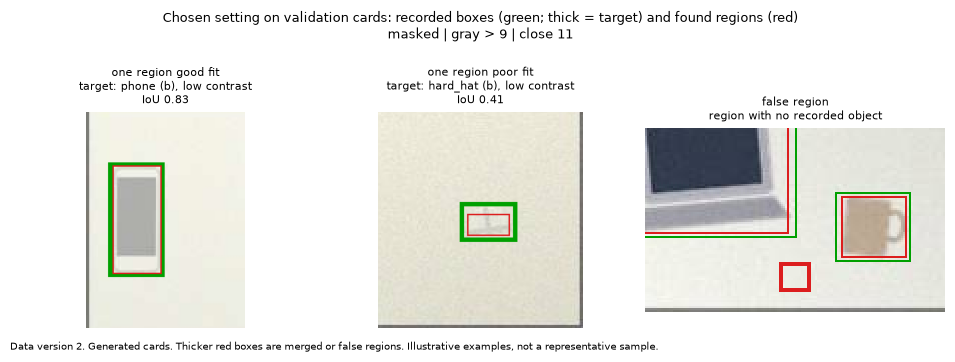

,card_id,object_index,region,object,style,size_band,contrast_band,best_iou,x0,y0,x1,y1
outcome,,,,,,,,,,,,
one_region_good_fit,KIT-0523,3,<NA>,phone,b,large,low,0.828,15,79,54,158
one_region_poor_fit,KIT-0437,2,<NA>,hard_hat,b,small,low,0.413,397,235,436,262
false_region,KIT-0031,<NA>,4,no object,-,-,-,0.000,333,295,349,310


In [7]:
example_rng = np.random.default_rng(2026)
MARGIN, MIN_VIEW = 30, 150          # crop margin around the target and its regions, and the smallest panel size (pixels)
val_kit = kit_final[kit_final["split"] == "validation"]
files_by_card = manifest.set_index("card_id")["file_name"]
present_outcomes = [o for o in OUTCOMES if (val_kit["outcome"] == o).any()]
val_false = final_regions[(final_regions["split"] == "validation") & (final_regions["region_type"] == "false")]
panels = present_outcomes + (["false_region"] if len(val_false) else [])
fig, axes = plt.subplots(1, len(panels), figsize=(3.2 * len(panels), 3.4))
axes = np.atleast_1d(axes)
example_rows = []
for ax, outcome in zip(axes, panels):
    if outcome == "false_region":       # a region that overlaps no recorded object
        fr = val_false.iloc[int(example_rng.integers(len(val_false)))]
        row = pd.Series({"card_id": fr.card_id, "object": "no object", "style": "-", "contrast_band": "-",
                         "size_band": "-", "best_iou": 0.0})
        target = pd.Series({"x0": fr.x0, "y0": fr.y0, "x1": fr.x1, "y1": fr.y1})
        card_objs = dev_objects[dev_objects["card_id"] == fr.card_id].reset_index(drop=True)
        target_index = None
    else:
        pool = val_kit[val_kit["outcome"] == outcome]
        row = pool.iloc[int(example_rng.integers(len(pool)))]
        card_objs = dev_objects[dev_objects["card_id"] == row.card_id].reset_index(drop=True)
        target_index = int(row.object_index)
        target = card_objs.iloc[target_index]
    target_box = (int(target.x0), int(target.y0), int(target.x1), int(target.y1))
    card_regions = final_regions[final_regions["card_id"] == row.card_id]
    # Crop to the target plus every found region overlapping it (and, for a merge, the other objects it covers)
    related = [target_box] + [(r.x0, r.y0, r.x1, r.y1) for r in card_regions.itertuples()
                              if overlaps((r.x0, r.y0, r.x1, r.y1), target_box)]
    for rb in list(related[1:]):
        related += [(o.x0, o.y0, o.x1, o.y1) for o in card_objs.itertuples() if overlaps(rb, (o.x0, o.y0, o.x1, o.y1))]
    x0, y0 = min(b[0] for b in related) - MARGIN, min(b[1] for b in related) - MARGIN
    x1, y1 = max(b[2] for b in related) + MARGIN, max(b[3] for b in related) + MARGIN
    grow_x, grow_y = max(0, MIN_VIEW - (x1 - x0)) // 2, max(0, MIN_VIEW - (y1 - y0)) // 2
    x0, x1 = max(0, x0 - grow_x), min(480, x1 + grow_x)
    y0, y1 = max(0, y0 - grow_y), min(320, y1 + grow_y)

    card = Image.open(KIT / "images" / files_by_card[row.card_id]).convert("RGB")
    draw = ImageDraw.Draw(card)
    for j, o in enumerate(card_objs.itertuples()):
        draw.rectangle([o.x0, o.y0, o.x1 - 1, o.y1 - 1], outline=(0, 160, 0), width=3 if j == target_index else 1)
    for r in card_regions.itertuples():
        draw.rectangle([r.x0, r.y0, r.x1 - 1, r.y1 - 1], outline=(220, 30, 30), width=1 if r.region_type == "single" else 2)
    ax.imshow(card.crop((x0, y0, x1, y1)))
    subtitle = ("region with no recorded object" if outcome == "false_region"
                else f"target: {row.object} ({row.style}), {row.contrast_band} contrast\nIoU {row.best_iou:.2f}")
    ax.set_title(f"{outcome.replace('_', ' ')}\n{subtitle}", fontsize=8)
    ax.axis("off")
    example_rows.append({"outcome": outcome, "card_id": row.card_id,
                         "object_index": target_index,
                         "region": int(fr["region"]) if outcome == "false_region" else None,
                         "object": row.object, "style": row.style, "size_band": row.size_band,
                         "contrast_band": row.contrast_band, "best_iou": round(float(row.best_iou), 3),
                         "x0": target_box[0], "y0": target_box[1], "x1": target_box[2], "y1": target_box[3]})
fig.suptitle(f"Chosen setting on validation cards: recorded boxes (green; thick = target) and found regions (red)\n{CHOSEN}", fontsize=9)
fig.text(0.01, -0.02, "Data version 2. Generated cards. Thicker red boxes are merged or false regions. "
         "Illustrative examples, not a representative sample.", fontsize=7)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "segmentation_examples_validation.png", dpi=150, bbox_inches="tight")
plt.show()
examples = pd.DataFrame(example_rows).astype({"object_index": "Int64", "region": "Int64"})
examples.to_csv(OUTPUT_DIR / "segmentation_examples_validation.csv", index=False)
display(examples.set_index("outcome"))